# Reading NetCDF files with xarray

Most gridded climate and satellite data come as **NetCDF** files (`.nc`, `.nc4`): rainfall, temperature,
reanalysis, gravity (GRACE), air quality. This notebook opens two real files over Punjab, from the first notebook,
and teaches what is inside them and how to work with them using **xarray**:

* the anatomy of a NetCDF file: dimensions, coordinates, variables, attributes, and the CF conventions that give them
  meaning;
* decoding: units, time axes (including an awkward one), scale factors and missing values;
* selecting by place and time, and why the order of latitudes matters;
* time: monthly to annual totals, climatologies and anomalies;
* averaging over an area properly (weighted by cell area);
* putting two grids on the same grid, and writing a tidy file of your own.

**Libraries.** *xarray* is pandas for labelled multi-dimensional arrays; *netCDF4* reads the files; *numpy*, *pandas*
and *matplotlib* as usual.

In [1]:
import importlib.util, subprocess, sys
need = {"xarray": "xarray", "netCDF4": "netCDF4", "cftime": "cftime"}
missing = [p for m, p in need.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, requests
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("gd_data"); DATA.mkdir(exist_ok=True)
RAW = "https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/gridded-data/notebooks/gd_data/"
for n in ("chirps_punjab_monthly.nc", "era5land_punjab_monthly.nc"):     # made by notebook 1; fetched if you start here
    if not (DATA / n).exists():
        (DATA / n).write_bytes(requests.get(RAW + n, timeout=600).content)

# What is inside a NetCDF file

A NetCDF file is a small self-describing database of arrays:

* **dimensions**: named axis lengths, e.g. `time: 288`, `latitude: 81`, `longitude: 101`;
* **coordinates**: the values along each dimension (the 288 dates, the 81 latitudes);
* **variables**: the data arrays, each laid out on some of the dimensions, e.g. `tp(time, latitude, longitude)`;
* **attributes**: notes attached to the file or to a variable: units, long names, where it came from.

The **CF conventions** (Climate and Forecast) standardise those notes, so programs know that `units: "m"` is metres,
that `standard_name: "precipitation_amount"` is rainfall, and how to read the time axis. Look before you compute:
printing a dataset shows all four parts.

In [2]:
era = xr.open_dataset(DATA / "era5land_punjab_monthly.nc")
era

<xarray.Dataset> Size: 19MB
Dimensions:     (valid_time: 288, latitude: 81, longitude: 101)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 2001-01-01 ... 2024-12-01
  * latitude    (latitude) float64 648B 34.0 33.9 33.8 33.7 ... 26.2 26.1 26.0
  * longitude   (longitude) float64 808B 70.0 70.1 70.2 70.3 ... 79.8 79.9 80.0
    expver      (valid_time) <U4 5kB ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 9MB ...
    t2m         (valid_time, latitude, longitude) float32 9MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-21T20:33 GRIB to CDM+CF via cfgrib-0.9.1...

In [3]:
print("dimensions:", dict(era.sizes))
print("tp units:", era.tp.attrs.get("units"), "| t2m units:", era.t2m.attrs.get("units"))
print("first and last latitude:", float(era.latitude[0]), float(era.latitude[-1]), "(north to south)")

dimensions: {'valid_time': 288, 'latitude': 81, 'longitude': 101}
tp units: m | t2m units: K
first and last latitude: 34.0 26.0 (north to south)


Two things to note already. ERA5-Land's monthly rainfall `tp` is in **metres per day** (the mean daily total of the
month), not millimetres per month: we must convert. And its latitudes run **north to south**.

# Decoding the time axis

Time in NetCDF is stored as numbers counted from a reference: `units: "days since 1900-01-01"`. xarray turns these into
dates automatically when the file follows CF. The CHIRPS file from the IRI server shows what happens when it does not:

In [4]:
ch_raw = xr.open_dataset(DATA / "chirps_punjab_monthly.nc", decode_times=False)
print(ch_raw.T.attrs["units"], "| calendar:", ch_raw.T.attrs["calendar"], "| first values:", ch_raw.T.values[:3])

months since 1960-01-01 | calendar: 360 | first values: [492.5 493.5 494.5]


*Months since 1960-01-01* in a *360-day calendar*: month numbers, with half-months marking the middle. Standard date
libraries cannot read "months since", so we decode it ourselves: whole months after January 1960.

In [5]:
months = np.floor(ch_raw.T.values).astype(int)
dates = pd.to_datetime([f"{1960 + m // 12}-{m % 12 + 1:02d}-01" for m in months])
ch = (ch_raw.assign_coords(T=dates)
      .rename({"T": "time", "Y": "latitude", "X": "longitude", "precipitation": "pr"}))
print(ch.time.values[[0, -1]], "| units:", ch.pr.attrs.get("units"))

['2001-01-01T00:00:00.000000000' '2024-12-01T00:00:00.000000000'] | units: mm/month


CHIRPS monthly is in **mm per month**. To compare with ERA5-Land, convert ERA5-Land to the same unit: metres per day x
1000 x days in the month. Then give both the same names, and the same latitude order (south to north).

In [6]:
era = era.rename({"valid_time": "time"}).drop_vars(["number", "expver"], errors="ignore")
days = era.time.dt.days_in_month
era["pr"] = era.tp * 1000 * days
era.pr.attrs = {"units": "mm/month", "long_name": "precipitation"}
era["t2m"] = era.t2m - 273.15; era.t2m.attrs = {"units": "degC", "long_name": "2 m air temperature"}
era = era[["pr", "t2m"]].sortby("latitude")
ch = ch.sortby("latitude")
print("ERA5-Land mean monthly rain over the box:", round(float(era.pr.mean()), 1), "mm | CHIRPS:", round(float(ch.pr.mean()), 1), "mm")

ERA5-Land mean monthly rain over the box: 56.7 mm | CHIRPS: 49.1 mm


# Selecting by place and time

`sel` picks by coordinate values; `isel` by position. For a point that is not exactly on the grid, ask for the nearest
cell; for a range, use `slice`. With latitudes sorted south to north, `slice(29, 32)` works; with them north to south
the same slice silently returns nothing, which is why we sorted.

box shape (time, lat, lon): (36, 60, 61)


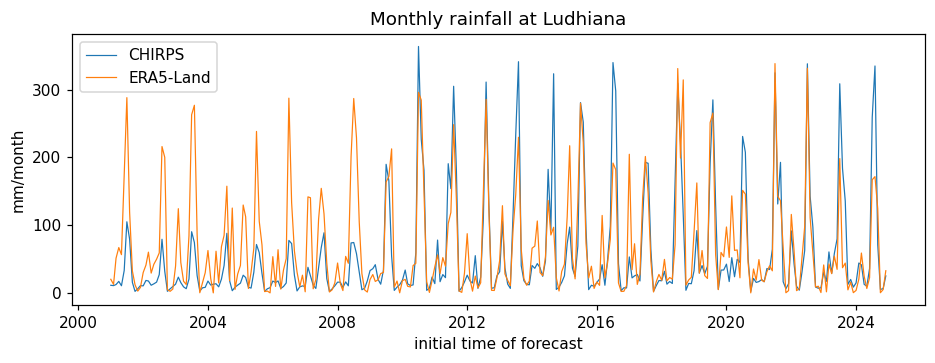

In [7]:
ludhiana = dict(longitude=75.85, latitude=30.90)
pt_ch = ch.pr.sel(**ludhiana, method="nearest").drop_vars(["latitude", "longitude"])    # the nearest cells differ slightly
pt_era = era.pr.sel(**ludhiana, method="nearest").drop_vars(["latitude", "longitude"])   # between grids: drop them to combine
box = ch.pr.sel(latitude=slice(29, 32), longitude=slice(74, 77), time=slice("2010", "2012"))
print("box shape (time, lat, lon):", box.shape)
fig, ax = plt.subplots(figsize=(10, 3.2))
pt_ch.plot(ax=ax, label="CHIRPS", lw=.8); pt_era.plot(ax=ax, label="ERA5-Land", lw=.8)
ax.set_title("Monthly rainfall at Ludhiana"); ax.set_ylabel("mm/month"); ax.legend(); plt.show()

# Time: totals, climatologies and anomalies

* **Annual totals**: `resample(time="YS").sum()` (YS: year start).
* **Climatology**: the average for each calendar month over a base period: `groupby("time.month").mean()`.
* **Anomaly**: each month minus its climatology: what was unusual about that month.
* **Seasons**: `groupby("time.season")` gives DJF, MAM, JJA, SON; the monsoon (June-September) is picked with a mask.

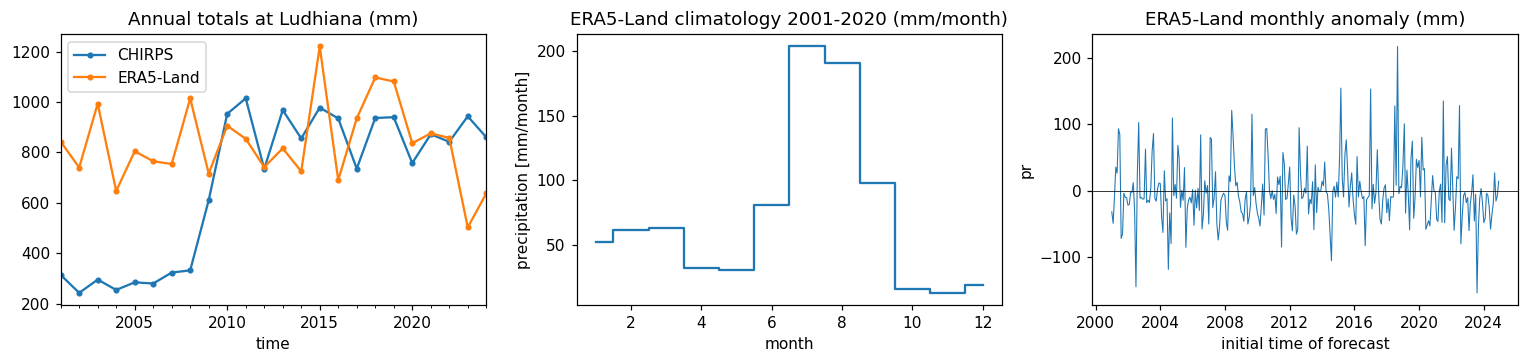

time       2001-01-01  2005-01-01  2008-01-01  2009-01-01  2010-01-01  \
CHIRPS          314.0       284.0       332.0       611.0       953.0   
ERA5-Land       843.0       805.0      1015.0       716.0       906.0   

time       2011-01-01  2016-01-01  2024-01-01  
CHIRPS         1015.0       935.0       860.0  
ERA5-Land       854.0       691.0       637.0  


In [8]:
annual = xr.Dataset({"CHIRPS": pt_ch.resample(time="YS").sum(), "ERA5-Land": pt_era.resample(time="YS").sum()})
clim = pt_era.sel(time=slice("2001", "2020")).groupby("time.month").mean()
anom = pt_era.groupby("time.month") - clim
jjas = pt_era.where(pt_era.time.dt.month.isin([6, 7, 8, 9]), drop=True).resample(time="YS").sum()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
annual.to_dataframe()[["CHIRPS", "ERA5-Land"]].plot(ax=ax[0], marker="o", ms=3); ax[0].set_title("Annual totals at Ludhiana (mm)")
clim.plot.step(ax=ax[1], where="mid"); ax[1].set_title("ERA5-Land climatology 2001-2020 (mm/month)")
anom.plot(ax=ax[2], lw=.7); ax[2].axhline(0, color="k", lw=.5); ax[2].set_title("ERA5-Land monthly anomaly (mm)")
plt.tight_layout(); plt.show()
print(annual.to_dataframe()[["CHIRPS", "ERA5-Land"]].round(0).T.iloc[:, [0, 4, 7, 8, 9, 10, 15, 23]])

Look at the annual totals: CHIRPS jumps from about 300-400 mm to about 800 mm between 2008 and 2010 and stays there,
while ERA5-Land does not. A real climate shift would show in both. Notebook 3 tests this properly.

# Averaging over an area: weight by cell size

A degree of longitude is shorter near the poles, so grid cells further north are smaller. An area average must weight
each cell by its area, which on a regular latitude-longitude grid is proportional to the cosine of latitude. Over
26-34 N the difference is small (about 2 %), but over a large region or the globe it matters.

In [9]:
w = np.cos(np.deg2rad(era.latitude))
plain = era.pr.mean(["latitude", "longitude"])
weighted = era.pr.weighted(w).mean(["latitude", "longitude"])
print("mean monthly rain, plain vs area-weighted:", round(float(plain.mean()), 2), round(float(weighted.mean()), 2), "mm")

mean monthly rain, plain vs area-weighted: 56.67 56.37 mm


# Putting two grids on one grid

CHIRPS is on a 0.05 degree grid, ERA5-Land on 0.1 degree. To compare them cell by cell, bring one onto the other's grid.
For rainfall, averaging the fine cells inside each coarse cell (`coarsen`) keeps totals right; interpolating
(`interp_like`) is quicker but can miss local extremes. Here CHIRPS is averaged to 0.1 degree, then aligned exactly.

In [10]:
ch01 = ch.pr.coarsen(latitude=2, longitude=2, boundary="trim").mean()
ch01 = ch01.interp_like(era.pr.isel(time=0), method="nearest")      # snap to ERA5-Land's exact coordinates
both = xr.Dataset({"chirps": ch01, "era5": era.pr}).sel(time=slice("2001", "2024"))
both = both.dropna("latitude", how="all").dropna("longitude", how="all")
print(both)

<xarray.Dataset> Size: 28MB
Dimensions:    (time: 288, longitude: 101, latitude: 81)
Coordinates:
  * time       (time) datetime64[ns] 2kB 2001-01-01 2001-02-01 ... 2024-12-01
  * longitude  (longitude) float64 808B 70.0 70.1 70.2 70.3 ... 79.8 79.9 80.0
  * latitude   (latitude) float64 648B 26.0 26.1 26.2 26.3 ... 33.8 33.9 34.0
Data variables:
    chirps     (time, latitude, longitude) float32 9MB nan nan nan ... nan nan
    era5       (time, latitude, longitude) float64 19MB 0.02746 ... 6.926


# Writing your own NetCDF file

Keep the result small and self-describing: units and long names on every variable, a note on where it came from, and
compression. Anyone opening the file later (including you) then knows what it is.

In [11]:
both["chirps"].attrs = {"units": "mm/month", "long_name": "CHIRPS v2.0 precipitation, averaged to 0.1 deg"}
both["era5"].attrs = {"units": "mm/month", "long_name": "ERA5-Land total precipitation (monthly means x days)"}
both.attrs = {"title": "Monthly rainfall over Punjab, two products on one grid", "Conventions": "CF-1.8",
              "source": "CHIRPS v2.0 via IRI Data Library; ERA5-Land via Copernicus CDS",
              "history": f"made by gd_netcdf_xarray.ipynb on {pd.Timestamp.now():%Y-%m-%d}"}
enc = {v: {"zlib": True, "complevel": 4, "dtype": "float32"} for v in both.data_vars}
both.to_netcdf(DATA / "punjab_rain_two_products.nc", encoding=enc)
print(round((DATA / "punjab_rain_two_products.nc").stat().st_size / 1e6, 1), "MB written")

11.6 MB written
